Universidad de Buenos Aires

FIUBA - CEIA

Vision por computadora 1

Azar Miguel Augusto

a2702

---

# **Trabajo práctico 2**

Resolucion del ejercicio propuesto

El archivo provisto es:
- focus_video.mov




# 1. Configuración

Importo las bibliotecas y defino los parámetros del análisis.

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

VIDEO_PATH = "/content/focus_video.mov"

# La ROI ocupa el 25 % del ancho y el 25 % del alto: 6,25 % del área.
ROI_WIDTH_RATIO = 0.25
ROI_HEIGHT_RATIO = 0.25

# Criterio para definir la región temporal enfocada.
FOCUS_RATIO = 0.90

# Parámetros de Unsharp Masking.
UNSHARP_AMOUNT = 1.0
UNSHARP_KERNEL = (5, 5)
UNSHARP_SIGMA = 1.0

print("Configuracion lista.")
print("Archivo de video a analizar:", VIDEO_PATH)

Configuracion lista.
Archivo de video a analizar: /content/focus_video.mov


**Resultado:** el video se analizará con un umbral del 90 % del valor máximo. La ROI definida en los parámetros ocupa el 25 % del ancho y el 25 % del alto, es decir, el 6,25 % del área total.

# 2. Carga del video

Abro con OpenCV el video. El video se debe subir manualmente en la carpeta `content` si se ejeccuta desde Google Colab. En esta celda se leen todos sus fotogramas y se guardan en memoria para analizarlos.

In [ ]:
if not os.path.exists(VIDEO_PATH):
    raise FileNotFoundError(
        f"No se encontró {VIDEO_PATH}. Subir focus_video.mov a la carpeta /content de Colab."
    )

capture = cv2.VideoCapture(VIDEO_PATH)

if not capture.isOpened():
    raise RuntimeError("OpenCV no pudo abrir el video.")

fps = capture.get(cv2.CAP_PROP_FPS)
reported_frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))

frames = []
while True:
    success, frame = capture.read()
    if not success:
        break
    frames.append(frame)

capture.release()

if not frames:
    raise RuntimeError("No se pudo leer ningún fotograma del video.")

print(f"Resolución: {width} x {height} píxeles")
print(f"FPS: {fps:.2f}")
print(f"Fotogramas informados por el archivo: {reported_frames}")
print(f"Fotogramas leídos: {len(frames)}")
print(f"Duración aproximada: {len(frames) / fps:.2f} segundos")

Resolución: 640 x 360 píxeles
FPS: 29.97
Fotogramas informados por el archivo: 171
Fotogramas leídos: 171
Duración aproximada: 5.71 segundos


**Resultado:** se leyeron correctamente los 171 fotogramas del video, con una resolución de 640 × 360 píxeles y una frecuencia de 29,97 FPS. La duración calculada es de 5,71 segundos.

# 3. Revision de algunos fotogramas

Muestro el primer fotograma, uno del centro del video y el último. Esto permite comprobar que el archivo se leyó correctamente.

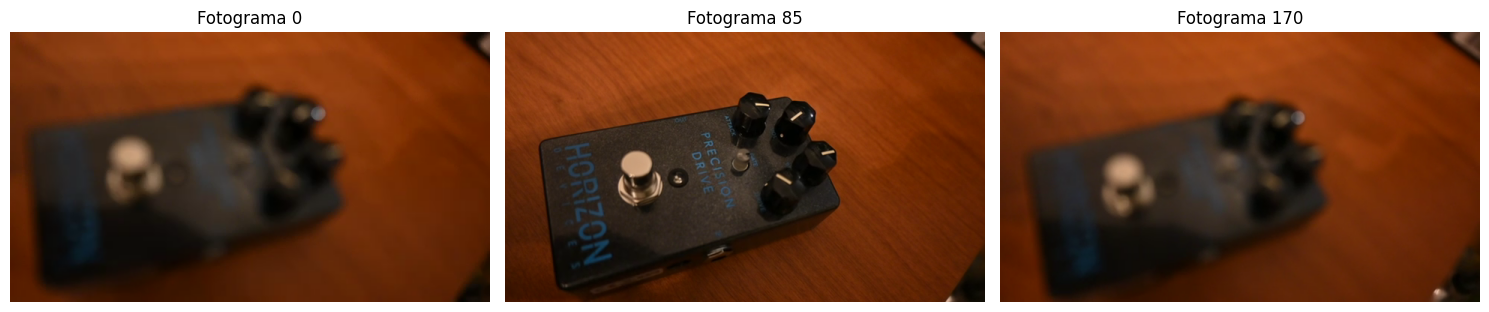

In [ ]:
sample_indices = sorted(set([0, len(frames) // 2, len(frames) - 1]))

fig, axes = plt.subplots(1, len(sample_indices), figsize=(15, 4))
if len(sample_indices) == 1:
    axes = [axes]

for ax, index in zip(axes, sample_indices):
    image_rgb = cv2.cvtColor(frames[index], cv2.COLOR_BGR2RGB)
    ax.imshow(image_rgb)
    ax.set_title(f"Fotograma {index}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**Resultado:** el fotograma 0 está desenfocado, el 85 muestra el objeto más nítido y el 170 vuelve a estar desenfocado. La secuencia visual confirma el cambio de enfoque que se analizará en las siguientes secciones.

# 4. Implementacion de la métrica FM

Implemento los pasos que sigue el paper, que son: Transformada de Fourier, centrado del espectro, valor absoluto, umbral igual al máximo dividido por 1000 y conteo de los valores que superan ese umbral. La métrica es ese conteo dividido por la cantidad total de píxeles.

In [ ]:
def calcular_fm(imagen_gris):
    """Calcula la métrica FM del paper para una imagen en escala de grises."""
    transformada = np.fft.fft2(imagen_gris)
    espectro_centrado = np.fft.fftshift(transformada)
    amplitud = np.abs(espectro_centrado)

    valor_maximo = np.max(amplitud)
    umbral = valor_maximo / 1000.0

    cantidad_superior_umbral = np.count_nonzero(amplitud > umbral)
    alto, ancho = imagen_gris.shape

    fm = cantidad_superior_umbral / (alto * ancho)
    return float(fm)


# Prueba de la función con el primer fotograma.
primer_fotograma_gris = cv2.cvtColor(frames[0], cv2.COLOR_BGR2GRAY)
print(f"FM del primer fotograma: {calcular_fm(primer_fotograma_gris):.6f}")

FM del primer fotograma: 0.007122


**Resultado:** la métrica FM del primer fotograma es **0,007122**. La función devuelve un único valor numérico para cada imagen en escala de grises.

# 5. Experimento 1: fotograma completo

Se convierte cada fotograma a escala de grises y se calcula FM sobre toda su superficie.

In [ ]:
fm_completo = []

for frame in frames:
    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    fm_completo.append(calcular_fm(gris))

fm_completo = np.array(fm_completo)

print(f"Mediciones calculadas: {len(fm_completo)}")
print(f"FM mínima: {fm_completo.min():.6f}")
print(f"FM máxima: {fm_completo.max():.6f}")
print(f"Fotograma del máximo: {int(np.argmax(fm_completo))}")

Mediciones calculadas: 171
FM mínima: 0.006819
FM máxima: 0.028624
Fotograma del máximo: 109


**Resultado:** se calcularon 171 valores FM. El mínimo es **0,006819** y el máximo es **0,028624**, que aparece en el fotograma **109**. La medición del fotograma completo alcanza su mayor valor en esa posición.

# 6. Experimento 2: región central (ROI)

Se recorta el centro de cada fotograma. La región ocupa el 25 % del ancho y el 25 % del alto, equivalente al 6,25 % del área total. Se calcula FM únicamente sobre ese recorte.

Tamaño de la ROI: 160 x 90 píxeles
Área de la ROI: 6.25 % del fotograma
FM mínima en la ROI: 0.048889
FM máxima en la ROI: 0.431181
Fotograma del máximo: 111


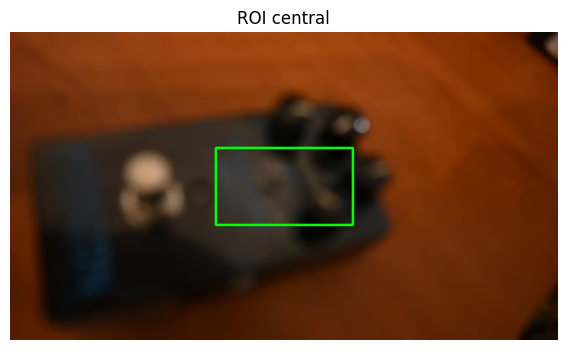

In [ ]:
roi_width = int(width * ROI_WIDTH_RATIO)
roi_height = int(height * ROI_HEIGHT_RATIO)

x_start = (width - roi_width) // 2
y_start = (height - roi_height) // 2
x_end = x_start + roi_width
y_end = y_start + roi_height

fm_roi = []

for frame in frames:
    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    roi = gris[y_start:y_end, x_start:x_end]
    fm_roi.append(calcular_fm(roi))

fm_roi = np.array(fm_roi)
roi_area_percentage = (roi_width * roi_height) / (width * height) * 100

print(f"Tamaño de la ROI: {roi_width} x {roi_height} píxeles")
print(f"Área de la ROI: {roi_area_percentage:.2f} % del fotograma")
print(f"FM mínima en la ROI: {fm_roi.min():.6f}")
print(f"FM máxima en la ROI: {fm_roi.max():.6f}")
print(f"Fotograma del máximo: {int(np.argmax(fm_roi))}")

# Se muestra la ROI sobre el primer fotograma.
frame_roi_view = frames[0].copy()
cv2.rectangle(frame_roi_view, (x_start, y_start), (x_end, y_end), (0, 255, 0), 2)
plt.figure(figsize=(8, 4))
plt.imshow(cv2.cvtColor(frame_roi_view, cv2.COLOR_BGR2RGB))
plt.title("ROI central")
plt.axis("off")
plt.show()

**Resultado:** la ROI mide **160 × 90 píxeles** y representa el **6,25 %** del fotograma. Su FM mínima es **0,048889** y la máxima es **0,431181**, registrada en el fotograma **111**. El rectángulo verde muestra la región central analizada.

# 7. Detección de la región de máximo enfoque

Defino como enfocada la región continua alrededor del máximo cuya FM sea al menos el 90 % del valor máximo. El procedimiento se aplica por separado a las dos mediciones.

In [ ]:
def detectar_region_enfoque(valores, ratio=FOCUS_RATIO):
    """Devuelve inicio, fin, máximo y umbral de la región enfocada."""
    valores = np.asarray(valores)
    indice_maximo = int(np.argmax(valores))
    valor_maximo = float(valores[indice_maximo])
    umbral = valor_maximo * ratio

    inicio = indice_maximo
    fin = indice_maximo

    while inicio > 0 and valores[inicio - 1] >= umbral:
        inicio -= 1

    while fin < len(valores) - 1 and valores[fin + 1] >= umbral:
        fin += 1

    return {
        "inicio": inicio,
        "fin": fin,
        "maximo": indice_maximo,
        "valor_maximo": valor_maximo,
        "umbral": float(umbral)
    }


region_completa = detectar_region_enfoque(fm_completo)
region_roi = detectar_region_enfoque(fm_roi)

def mostrar_region(nombre, region):
    print(nombre)
    print(f"  Inicio: fotograma {region['inicio']}")
    print(f"  Fin: fotograma {region['fin']}")
    print(f"  Máximo: fotograma {region['maximo']}")
    print(f"  Umbral: {region['umbral']:.6f}")

mostrar_region("Fotograma completo", region_completa)
mostrar_region("ROI central", region_roi)

Fotograma completo
  Inicio: fotograma 79
  Fin: fotograma 115
  Máximo: fotograma 109
  Umbral: 0.025762
ROI central
  Inicio: fotograma 105
  Fin: fotograma 113
  Máximo: fotograma 111
  Umbral: 0.388063


**Resultado:** con el umbral del 90 % del máximo, el análisis del fotograma completo detecta la región entre los fotogramas **79 y 115**, con máximo en el **109**. En la ROI central, la región va del fotograma **105 al 113**, con máximo en el **111**. La ROI identifica un intervalo más corto y concentrado.

# 8. Grafico de las mediciones

Muestro las dos curvas FM en función del número de fotograma. La línea horizontal indica el umbral y el área sombreada señala la región detectada como enfocada.

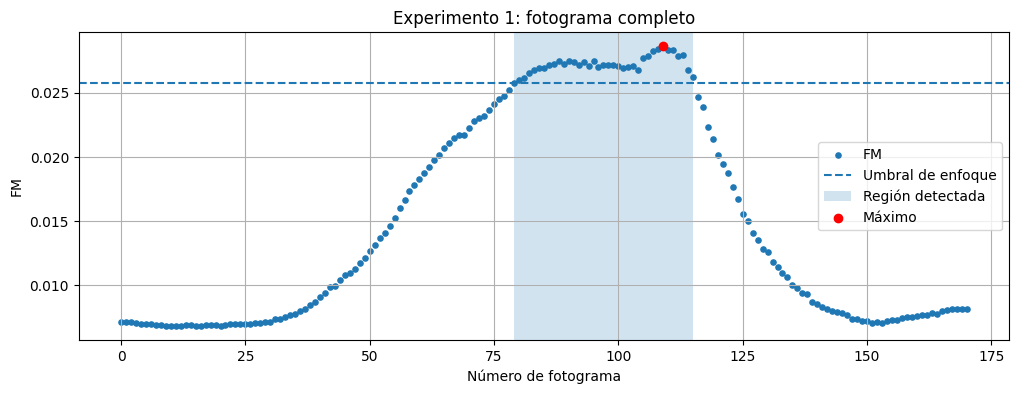

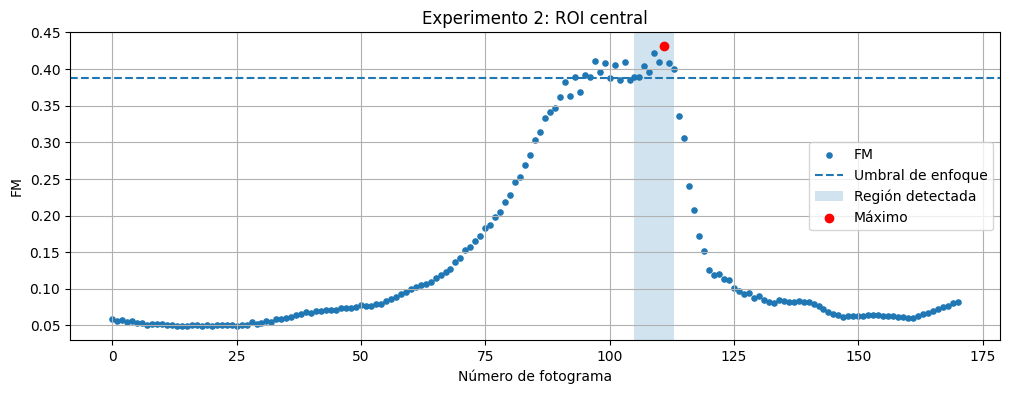

In [ ]:
def graficar_medicion(valores, region, titulo):
    indices = np.arange(len(valores))

    plt.figure(figsize=(12, 4))
    plt.scatter(indices, valores, label="FM", s=14)
    plt.axhline(region["umbral"], linestyle="--", label="Umbral de enfoque")
    plt.axvspan(region["inicio"], region["fin"], alpha=0.2, label="Región detectada")
    plt.scatter(
        region["maximo"],
        valores[region["maximo"]],
        color="red",
        zorder=3,
        label="Máximo"
    )
    plt.xlabel("Número de fotograma")
    plt.ylabel("FM")
    plt.title(titulo)
    plt.grid(True)
    plt.legend()
    plt.show()


graficar_medicion(fm_completo, region_completa, "Experimento 1: fotograma completo")
graficar_medicion(fm_roi, region_roi, "Experimento 2: ROI central")

**Resultado:** la curva del fotograma completo sube desde valores cercanos a 0,007, alcanza su máximo de **0,028624** en el fotograma 109 y luego desciende. La ROI presenta un pico más estrecho: alcanza **0,431181** en el fotograma 111 y cae rápidamente después. Las zonas sombreadas muestran los intervalos detectados con el umbral del 90 %.

# 9. Punto extra: Unsharp Masking

Tal como plantea el enunciado aplico Unsharp Masking a los fotogramas inmediatamente anteriores y posteriores a la región detectada. Si la FM de un fotograma procesado alcanza el umbral original, se incorpora al intervalo. El proceso continúa hacia afuera mientras se cumpla esa condición.

In [ ]:
def aplicar_unsharp_masking(imagen_gris, amount=UNSHARP_AMOUNT):
    desenfocada = cv2.GaussianBlur(
        imagen_gris,
        UNSHARP_KERNEL,
        UNSHARP_SIGMA
    )
    realzada = cv2.addWeighted(
        imagen_gris,
        1.0 + amount,
        desenfocada,
        -amount,
        0
    )
    return realzada


def calcular_fm_frame(frame, usar_roi=False):
    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    if usar_roi:
        gris = gris[y_start:y_end, x_start:x_end]

    return calcular_fm(gris)


def expandir_region_con_unsharp(frames, region, usar_roi=False):
    inicio = region["inicio"]
    fin = region["fin"]
    umbral_original = region["umbral"]
    evaluaciones = []

    # Examinar fotogramas anteriores al intervalo.
    while inicio > 0:
        candidato = inicio - 1
        gris = cv2.cvtColor(frames[candidato], cv2.COLOR_BGR2GRAY)
        realzada = aplicar_unsharp_masking(gris)

        if usar_roi:
            realzada = realzada[y_start:y_end, x_start:x_end]

        fm_realzada = calcular_fm(realzada)
        evaluaciones.append((candidato, fm_realzada))

        if fm_realzada >= umbral_original:
            inicio = candidato
        else:
            break

    # Examinar fotogramas posteriores al intervalo.
    while fin < len(frames) - 1:
        candidato = fin + 1
        gris = cv2.cvtColor(frames[candidato], cv2.COLOR_BGR2GRAY)
        realzada = aplicar_unsharp_masking(gris)

        if usar_roi:
            realzada = realzada[y_start:y_end, x_start:x_end]

        fm_realzada = calcular_fm(realzada)
        evaluaciones.append((candidato, fm_realzada))

        if fm_realzada >= umbral_original:
            fin = candidato
        else:
            break

    return {
        "inicio": inicio,
        "fin": fin,
        "umbral": umbral_original,
        "evaluaciones": evaluaciones
    }


region_completa_extra = expandir_region_con_unsharp(
    frames, region_completa, usar_roi=False
)
region_roi_extra = expandir_region_con_unsharp(
    frames, region_roi, usar_roi=True
)

print("Fotograma completo")
print(f"  Intervalo original: {region_completa['inicio']}–{region_completa['fin']}")
print(f"  Intervalo con Unsharp Masking: {region_completa_extra['inicio']}–{region_completa_extra['fin']}")

print("\nROI central")
print(f"  Intervalo original: {region_roi['inicio']}–{region_roi['fin']}")
print(f"  Intervalo con Unsharp Masking: {region_roi_extra['inicio']}–{region_roi_extra['fin']}")

print("\nCantidad de fotogramas adicionales evaluados:")
print(f"  Fotograma completo: {len(region_completa_extra['evaluaciones'])}")
print(f"  ROI central: {len(region_roi_extra['evaluaciones'])}")

Fotograma completo
  Intervalo original: 79–115
  Intervalo con Unsharp Masking: 69–118

ROI central
  Intervalo original: 105–113
  Intervalo con Unsharp Masking: 83–115

Cantidad de fotogramas adicionales evaluados:
  Fotograma completo: 15
  ROI central: 26


**Resultado:** al aplicar Unsharp Masking a los fotogramas contiguos a cada intervalo, la región del fotograma completo se amplía de **79–115** a **69–118**. En la ROI central se amplía de **105–113** a **83–115**. Se evaluaron 15 fotogramas adicionales para el fotograma completo y 26 para la ROI.

# 10. Comparacion de los intervalos finales

Aqui vuelvo a mostrar las curvas originales e indico los intervalos obtenidos después del punto extra. Las mediciones originales se mantienen sin modificar.

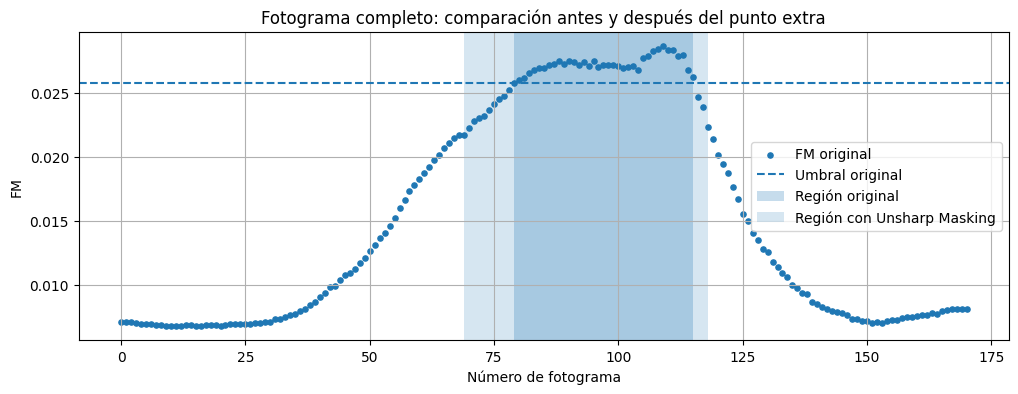

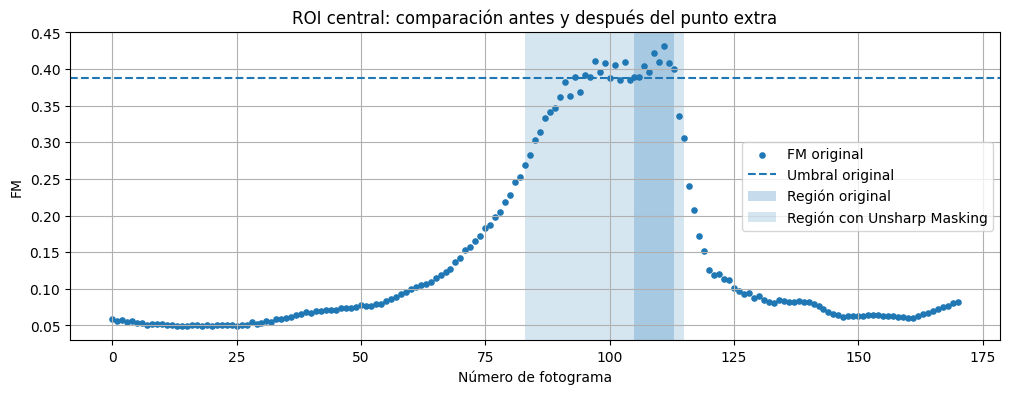

In [ ]:
def graficar_comparacion(valores, region_original, region_extra, titulo):
    indices = np.arange(len(valores))

    plt.figure(figsize=(12, 4))
    plt.scatter(indices, valores, label="FM original", s=14)
    plt.axhline(region_original["umbral"], linestyle="--", label="Umbral original")
    plt.axvspan(
        region_original["inicio"],
        region_original["fin"],
        alpha=0.25,
        label="Región original"
    )
    plt.axvspan(
        region_extra["inicio"],
        region_extra["fin"],
        alpha=0.18,
        label="Región con Unsharp Masking"
    )
    plt.xlabel("Número de fotograma")
    plt.ylabel("FM")
    plt.title(titulo)
    plt.grid(True)
    plt.legend()
    plt.show()


graficar_comparacion(
    fm_completo,
    region_completa,
    region_completa_extra,
    "Fotograma completo: comparación antes y después del punto extra"
)

graficar_comparacion(
    fm_roi,
    region_roi,
    region_roi_extra,
    "ROI central: comparación antes y después del punto extra"
)

**Resultado:** los gráficos comparan los intervalos originales con los ampliados. En ambos experimentos el intervalo obtenido con Unsharp Masking es más extenso. La curva y el umbral corresponden a las mediciones originales; el intervalo ampliado se obtuvo recalculando FM sobre los fotogramas realzados.

# 11. Comparacion entre imágenes originales y realzadas

Selecciono tres fotogramas: el límite inferior y el superior de la región ampliada con Unsharp Masking, y el fotograma de máximo enfoque original. Para cada uno muestro la imagen original y su versión realzada.

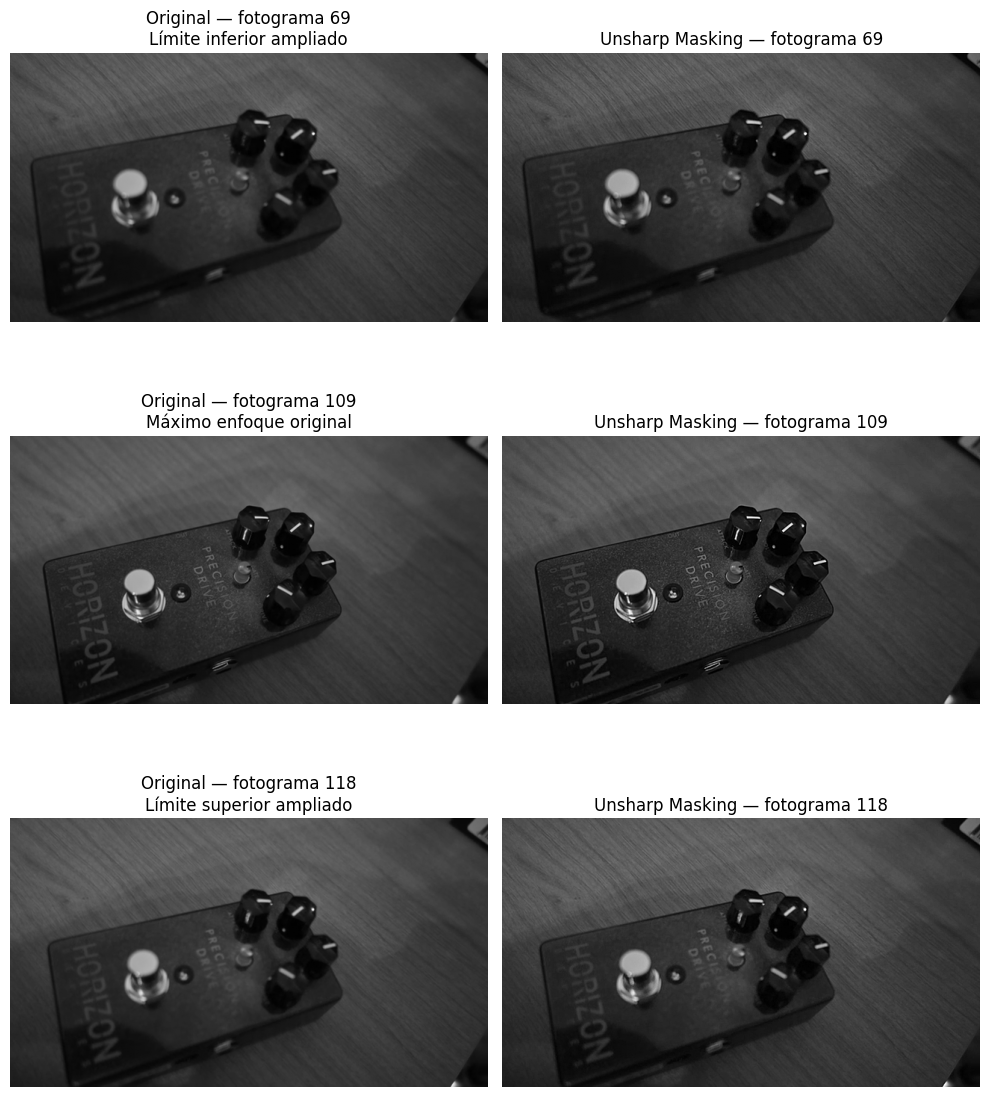

In [ ]:
indices_comparacion = [
    region_completa_extra["inicio"],
    region_completa["maximo"],
    region_completa_extra["fin"]
]

titulos_comparacion = [
    "Límite inferior ampliado",
    "Máximo enfoque original",
    "Límite superior ampliado"
]

fig, axes = plt.subplots(3, 2, figsize=(10, 12))

for fila, (indice, descripcion) in enumerate(zip(indices_comparacion, titulos_comparacion)):
    original = cv2.cvtColor(frames[indice], cv2.COLOR_BGR2GRAY)
    realzada = aplicar_unsharp_masking(original)

    axes[fila, 0].imshow(original, cmap="gray", vmin=0, vmax=255)
    axes[fila, 0].set_title(f"Original — fotograma {indice}\n{descripcion}")
    axes[fila, 0].axis("off")

    axes[fila, 1].imshow(realzada, cmap="gray", vmin=0, vmax=255)
    axes[fila, 1].set_title(f"Unsharp Masking — fotograma {indice}")
    axes[fila, 1].axis("off")

plt.tight_layout()
plt.show()

**Resultado:** se comparan los fotogramas de los dos límites de la región ampliada y el fotograma de máximo enfoque original. En cada fila, la imagen de la derecha es la versión realzada con Unsharp Masking. La comparación permite observar el efecto del realce en los límites y en el máximo.
- En el fotograma 69 la perilla (o potenciometro) tiene mas nitidez que la original.

- En el fotograma 109 se observa que el pulsador metalico tiene mas nitidez que en el original.

- En el fotogtrama 118 no alcanzo a notar mejora en la nitidez.

# 12. Resumen de resultados

Aqui reúno los principales valores de ambos experimentos para facilitar su comparación.

In [ ]:
import pandas as pd

resumen = pd.DataFrame([
    {
        "Experimento": "Fotograma completo",
        "Fotograma de máximo": region_completa["maximo"],
        "Inicio original": region_completa["inicio"],
        "Fin original": region_completa["fin"],
        "Inicio con Unsharp Masking": region_completa_extra["inicio"],
        "Fin con Unsharp Masking": region_completa_extra["fin"],
        "FM máxima": region_completa["valor_maximo"]
    },
    {
        "Experimento": "ROI central",
        "Fotograma de máximo": region_roi["maximo"],
        "Inicio original": region_roi["inicio"],
        "Fin original": region_roi["fin"],
        "Inicio con Unsharp Masking": region_roi_extra["inicio"],
        "Fin con Unsharp Masking": region_roi_extra["fin"],
        "FM máxima": region_roi["valor_maximo"]
    }
])

display(resumen)

,Experimento,Fotograma de máximo,Inicio original,Fin original,Inicio con Unsharp Masking,Fin con Unsharp Masking,FM máxima
0,Fotograma completo,109,79,115,69,118,0.028624
1,ROI central,111,105,113,83,115,0.431181


**Resultado:** el análisis del fotograma completo sitúa el máximo en el fotograma **109** y detecta inicialmente el intervalo **79–115**; después del punto extra, el intervalo es **69–118**. La ROI central sitúa el máximo en el fotograma **111** y detecta inicialmente **105–113**; con Unsharp Masking, el intervalo pasa a **83–115**. En este video, la ROI concentra la detección alrededor del máximo, mientras que el procesamiento adicional amplía ambos intervalos.